In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.tree import plot_tree

In [4]:
from pathlib import Path
import kagglehub

dataset_path = kagglehub.dataset_download('uciml/breast-cancer-wisconsin-data')
csv_files = list(Path(dataset_path).glob('*.csv'))
if not csv_files:
    raise FileNotFoundError('No CSV file was found in the downloaded Kaggle dataset.')
data = pd.read_csv(csv_files[0])
data.shape

C:\Users\yugen\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 48.6k/48.6k [00:00<00:00, 197kB/s]

Extracting files...


(569, 33)

In [5]:
display(data.head())
display(data.info())

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

None

In [6]:
target_column = next(
    (column for column in data.columns if column.strip().lower() in ['diagnosis', 'target']),
    data.columns[-1]
)
y = data[target_column]
identifier_columns = [
    column for column in data.columns
    if column.strip().lower() == 'id' or column.strip().lower().startswith('unnamed')
]
X = data.drop(columns=[target_column] + identifier_columns)
X = X.select_dtypes(include='number')
print('Feature shape:', X.shape)
print('Target column:', target_column)
print('Target values:')
display(y.value_counts())

Feature shape: (569, 30)
Target column: diagnosis
Target values:


diagnosis
B    357
M    212
Name: count, dtype: int64

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=41,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
model = RandomForestClassifier(
    n_estimators=10,
    criterion='entropy',
    random_state=0
)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [9]:
conf_mat = confusion_matrix(y_test, y_pred)
model_accuracy = accuracy_score(y_test, y_pred)
print('Confusion matrix:')
print(conf_mat)
print(f'Accuracy: {model_accuracy:.4f}')
print(f'Accuracy percentage: {model_accuracy:.2%}')
print(classification_report(y_test, y_pred))

Confusion matrix:
[[106   1]
 [  5  59]]
Accuracy: 0.9649
Accuracy percentage: 96.49%
              precision    recall  f1-score   support

           B       0.95      0.99      0.97       107
           M       0.98      0.92      0.95        64

    accuracy                           0.96       171
   macro avg       0.97      0.96      0.96       171
weighted avg       0.97      0.96      0.96       171



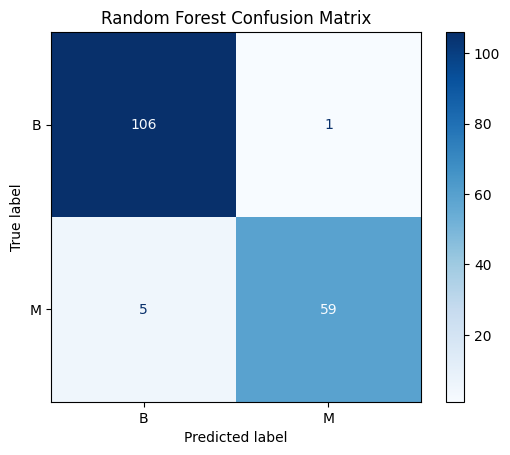

In [10]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', values_format='d')
plt.title('Random Forest Confusion Matrix')
plt.show()

,Importance
concave points_worst,0.206100
area_se,0.150597
concave points_mean,0.143297
area_worst,0.105415
concavity_worst,0.052996
perimeter_worst,0.041754
radius_se,0.037859
texture_worst,0.031400
radius_worst,0.024462
perimeter_mean,0.023201


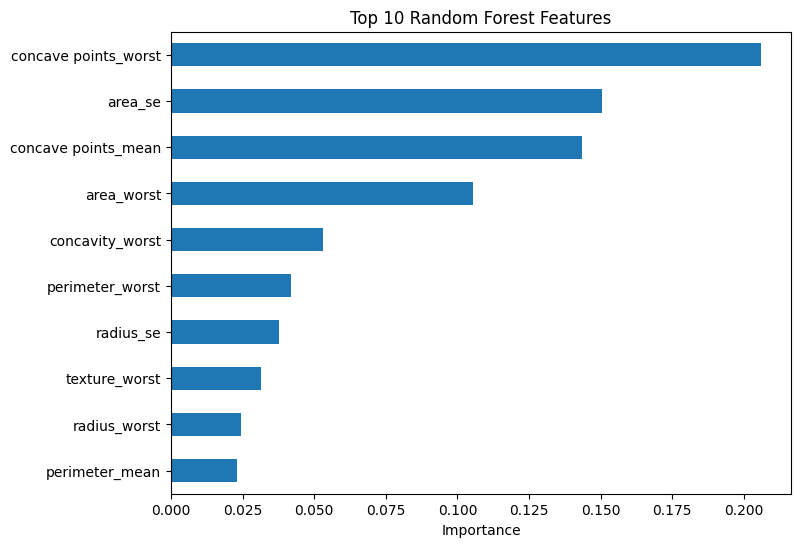

In [11]:
feature_importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
display(feature_importance.head(10).to_frame('Importance'))
feature_importance.head(10).sort_values().plot(kind='barh', figsize=(8, 6))
plt.xlabel('Importance')
plt.title('Top 10 Random Forest Features')
plt.show()

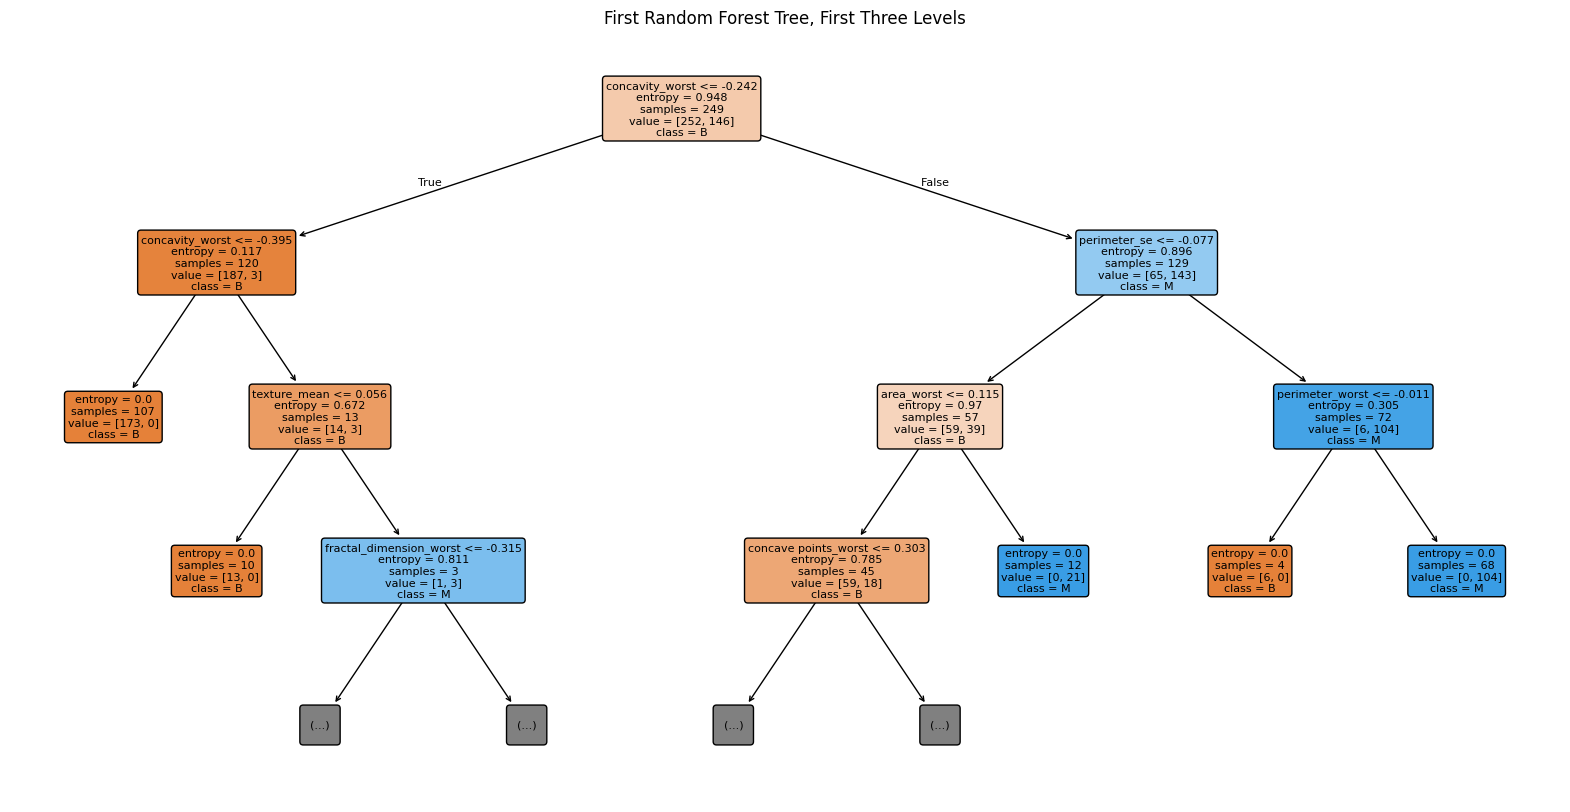

In [12]:
plt.figure(figsize=(20, 10))
plot_tree(
    model.estimators_[0],
    feature_names=X.columns,
    class_names=[str(value) for value in model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title('First Random Forest Tree, First Three Levels')
plt.show()

In [13]:
from collections import Counter

votes = ['Apple', 'Apple', 'Banana']
vote_counts = Counter(votes)
final_prediction, vote_total = vote_counts.most_common(1)[0]
print('Votes:', dict(vote_counts))
print('Final prediction:', final_prediction)
print('Number of votes:', vote_total)

Votes: {'Apple': 2, 'Banana': 1}
Final prediction: Apple
Number of votes: 2


### Answer

The apple (Class A) is likely to be selected most often because it receives two votes, while the banana (Class B) receives one.